In [1]:
import tensorflow as tf
import numpy as np

num_samples_per_class = 1000
negative_samples = np.random.multivariate_normal(
    mean=[0, 3], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)
positive_samples = np.random.multivariate_normal(
    mean=[3, 0], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)

In [2]:
inputs = np.vstack((negative_samples, positive_samples)).astype(np.float32)

In [3]:
targets = np.vstack(
    (
        np.zeros((num_samples_per_class, 1), dtype="float32"),
        np.ones((num_samples_per_class, 1), dtype="float32")
    )
)

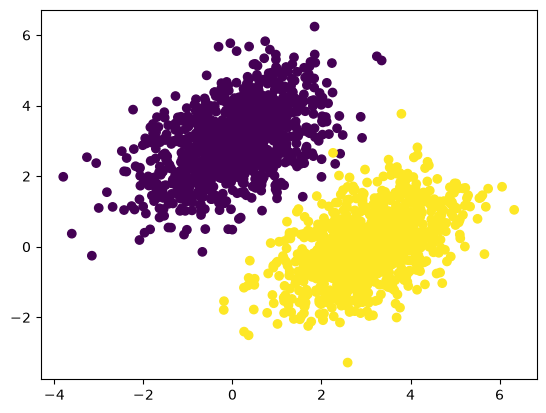

In [4]:
import matplotlib.pyplot as plt
plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0])
plt.show()

In [5]:
input_dim = 2
output_dim = 1

W = tf.Variable(initial_value=tf.random.uniform((input_dim, output_dim)))
b = tf.Variable(initial_value=tf.zeros((output_dim,)))

In [6]:
def model(inputs, W, b):
    return tf.matmul(inputs, W) + b

In [7]:
def mean_squared_error(targets, predictions):
    per_sample_losses = tf.square(targets - predictions)
    return tf.reduce_mean(per_sample_losses)

In [10]:
learning_rate = 0.1

@tf.function(jit_compile=True)
def training_step(inputs, targets, W, b):
    with tf.GradientTape() as tape:
        predictions = model(inputs, W, b)
        loss = mean_squared_error(targets, predictions)
    grad_loss_W, grad_loss_b = tape.gradient(loss, (W, b))
    W.assign_sub(grad_loss_W * learning_rate)
    b.assign_sub(grad_loss_b * learning_rate)
    return loss

In [11]:
for step in range(40):
    loss = training_step(inputs, targets, W, b)
    print(f"Loss for step {step}: {loss:.4f}")

I0000 00:00:1793933425.899712 1433024 service.cc:153] XLA service 0x7aa05add00 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793933425.899951 1433024 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793933426.096111 1433024 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Loss for step 0: 2.1419
Loss for step 1: 0.1927
Loss for step 2: 0.1142
Loss for step 3: 0.0985
Loss for step 4: 0.0912
Loss for step 5: 0.0854
Loss for step 6: 0.0802
Loss for step 7: 0.0755
Loss for step 8: 0.0712
Loss for step 9: 0.0673
Loss for step 10: 0.0637
Loss for step 11: 0.0604
Loss for step 12: 0.0574
Loss for step 13: 0.0546
Loss for step 14: 0.0521
Loss for step 15: 0.0498
Loss for step 16: 0.0477
Loss for step 17: 0.0458
Loss for step 18: 0.0440
Loss for step 19: 0.0424
Loss for step 20: 0.0409
Loss for step 21: 0.0396
Loss for step 22: 0.0384
Loss for step 23: 0.0372
Loss for step 24: 0.0362
Loss for step 25: 0.0353
Loss for step 26: 0.0344
Loss for step 27: 0.0336
Loss for step 28: 0.0329
Loss for step 29: 0.0322
Loss for step 30: 0.0316
Loss for step 31: 0.0311
Loss for step 32: 0.0306
Loss for step 33: 0.0301
Loss for step 34: 0.0297
Loss for step 35: 0.0293
Loss for step 36: 0.0290
Loss for step 37: 0.0287
Loss for step 38: 0.0284
Loss for step 39: 0.0281


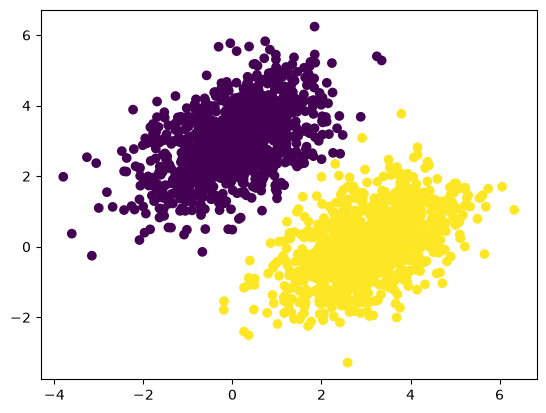

In [12]:
predictions = model(inputs, W, b)
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)
plt.show()

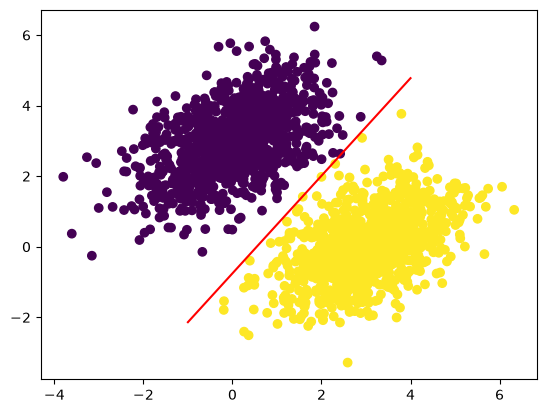

In [13]:
x = np.linspace(-1, 4, 100)
y = -W[0] / W[1] * x + (0.5 - b) / W[1]
plt.plot(x, y, "-r")
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)